In [ ]:
from scipy.linalg import eigh
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

def plot_truss(nodes, members, *, ax=None,
               show_nodes=True,
               node_size=40,
               member_color="k",
               node_color="red",
               lw=1.5,
               equal_aspect=True,
               show_node_ids=True,
               show_member_ids=True,
               node_offset=(0.02, 0.02),
               fontsize=9):

    if ax is None:
        fig, ax = plt.subplots()

    # ---- Plot members ----
    for m_id, (i, j) in enumerate(members):
        xi, yi = nodes[i]
        xj, yj = nodes[j]

        ax.plot([xi, xj], [yi, yj], member_color, lw=lw)

        # Member ID at midpoint (with normal offset)
        if show_member_ids:
            xm = 0.5 * (xi + xj)
            ym = 0.5 * (yi + yj)

            dx = xj - xi
            dy = yj - yi
            L = np.hypot(dx, dy)

            # Unit normal (perpendicular)
            nx = -dy / L
            ny =  dx / L

            offset = 0.04 * L   # scale with member length

            ax.text(
                xm + offset * nx,
                ym + offset * ny,
                f"M{m_id}",
                fontsize=fontsize,
                color="blue",
                ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.2",
                          fc="white", ec="blue", alpha=0.85),
                zorder=4
            )

    # ---- Plot nodes ----
    if show_nodes:
        xs = [n[0] for n in nodes]
        ys = [n[1] for n in nodes]
        ax.scatter(xs, ys, c=node_color, s=node_size, zorder=5)

        if show_node_ids:
            dx, dy = node_offset
            for i, (x, y) in enumerate(nodes):
                ax.text(
                    x + dx, y + dy, f"N{i}",
                    fontsize=fontsize,
                    color="black",
                    ha="left", va="bottom",
                    bbox=dict(boxstyle="round,pad=0.2",
                              fc="white", ec="black", alpha=0.9),
                    zorder=6
                )

    if equal_aspect:
        ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(True, linestyle="--", alpha=0.4)

    return ax


In [ ]:
def get_K(nodes, bars, A, E):
    nn = nodes.shape[0]
    ne = bars.shape[0]
    n_dof = 2 * nn
    delta = nodes[bars[:, 1], :] - nodes[bars[:, 0], :]
    length = np.sqrt((delta ** 2).sum(axis = 1))
    c = (delta.T / length).T                  # Direction Cosines
    ss = np.zeros([n_dof, n_dof])             # Initializing Global Stiffness Matrix
    for i in range(ne):
      aux = 2 * bars[i, :]
      index = np.r_[aux[0]:aux[0] + 2, aux[1]:aux[1] + 2]    # Getting the position of Element S.M. in Global S.M.

      # Element Stiffness
      x = c[i, 0]
      y = c[i, 1]
      t_bar = np.array([[x, y, 0, 0],
                        [0, 0, x, y]])

      k = E * (A[i] * 1e-4) / length[i] * np.array([[1, -1],
                                                    [-1, 1]])
      ke = t_bar.T @ k @ t_bar
      ss[np.ix_(index, index)] += ke     # Assembling the Global Matrices

    return ss

In [ ]:
nodes = np.array([[0., 0.],
                  [0., 1.],
                  [1., 0.],
                  [1., 1.],
                  [2., 0.],
                  [2., 1.],
                  [3., 0.],
                  [3., 1.]])
bars = np.array([[0, 3],
                 [0, 7],
                 [1, 2],
                 [1, 4],
                 [1, 6],
                 [2, 5],
                 [3, 5],
                 [3, 4],
                 [3, 6],
                 [4, 7],
                 [5, 6],
                 [5, 7]])

E = 2.1e11  # N/m2
A = np.ones([len(bars)]) * 40 # cm2
fixed = np.array([0, 1, 2, 3])
dofs = [i for i in range(2*len(nodes)) if i not in fixed]



In [ ]:
def get_displacements(K, f, dofs, disp_at=13, all=False):
  # kff = K[np.ix_(dofs, dofs)]
  u = np.linalg.solve(K, f) * 1000  # mm
  u_full = np.zeros((2*len(nodes), 1))
  u_full[dofs] = u
  if all:
    return u_full
  else:
    return u_full[disp_at]


In [ ]:
f0 = 1e5  # N
ff = np.zeros((2*len(nodes), 1))
ff[12] = f0
# f = ff[dofs]

<Axes: xlabel='X', ylabel='Y'>

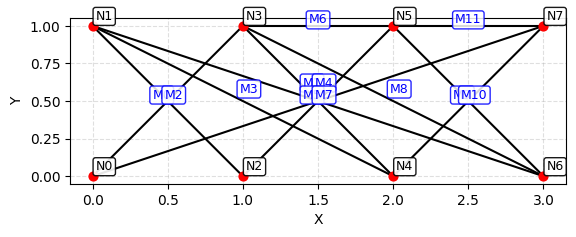

In [ ]:
plot_truss(nodes, bars)

In [ ]:
def check_stability(nodes, bars, dofs, A, E, ff, give_reason=False, give_displacement=False, tol=1e-8):
    reasons = []

    K_all = get_K(nodes, bars, A, E)
    K = K_all[np.ix_(dofs, dofs)]
    f = ff[dofs]

    ndof = K.shape[0]
    rank = np.linalg.matrix_rank(K)
    eigvals = np.linalg.eigvalsh(K)

    if rank < ndof:
        reasons.append(
            f"Rank deficiency: rank(K) = {rank} < ndof = {ndof} "
            "(mechanism or insufficient constraints)")

    min_eig = np.min(eigvals)
    if min_eig < tol:
        reasons.append(
            f"Near-zero/negative eigenvalue detected: min(eig) = {min_eig:.2e} "
            "(rigid body mode or mechanism)")

    if np.any(eigvals < 0):
        reasons.append(
            "Negative eigenvalues present (unstable equilibrium / improper stiffness)")

    if np.linalg.det(K) == 0:
      reasons.append("Stiffness Matrix is Singular")

    stable = len(reasons) == 0

    if stable:
      give_reason = False
      u = get_displacements(K, f, dofs, all=True)
      return True, u

    else:
      if give_reason:
        return False, reasons
      else:
        return False

In [ ]:
check_stability(nodes, bars, dofs, A, E, ff, give_reason=True, give_displacement=True)

(True,
 array([[ 0.        ],
        [ 0.        ],
        [ 0.        ],
        [ 0.        ],
        [ 8.27323189],
        [ 8.27323189],
        [-2.82969962],
        [ 2.40880273],
        [ 2.48439867],
        [ 6.96528661],
        [-3.00827105],
        [19.55473484],
        [13.16381108],
        [35.72681696],
        [-3.18684248],
        [12.38398963]]))